In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

In [21]:
df = pd.read_csv('../../data/processed/reg-szn/player_data_merged.csv')

#matching the minutes played requirement of our other analysis
df = df[df['advanced_MP'] >= 500].reset_index(drop=True)

#AI check for redundancy
print(df.shape)
print('One row per player:', df['player_id'].is_unique)

(379, 233)
One row per player: True


In [22]:
#Select attributes that are rates and describe play style, subject to change
features = {
    'advanced_USG%': 'usg',
    'advanced_AST%': 'ast',
    'advanced_TRB%': 'trb',
    'advanced_ORB%': 'orb',
    'advanced_BLK%': 'blk',
    'advanced_STL%': 'stl',
    'advanced_3PAr': 'three_rate',
    'advanced_FTr': 'ft_rate',
    'advanced_TS%': 'ts',
    'shooting_Dist.': 'shot_dist',
    'shooting_0-3': 'rim_rate'
}
#Assign a ranking (percentile score) to each player per stat, and adding rows to represent the min middle and max for each feature
pct = df[list(features)].rank(pct=True).mul(100).rename(columns=features)
pct.insert(0,'Player',df["Player"])
pct.describe().T[['min', '50%', 'max']]

,min,50%,max
usg,0.263852,50.000000,100.0
ast,0.263852,50.131926,100.0
trb,0.263852,50.791557,100.0
orb,0.263852,50.131926,100.0
blk,0.395778,49.340369,100.0
stl,0.263852,48.680739,100.0
three_rate,1.451187,50.131926,100.0
ft_rate,0.263852,50.131926,100.0
ts,0.263852,50.131926,100.0
shot_dist,0.263852,50.131926,100.0


In [23]:
#Cutoffs/attributes subject to change
def assign_DT_archetype(r):
    if r['usg'] >= 85 and r['ast'] >= 75:
        return 'Primary Creator'
    if r['usg'] >= 80:
        return 'Scorer'
    if r['ast'] >= 80:
        return 'Playmaker'
    if r['blk'] >= 80 and r['trb'] >= 70:
        return 'Rim Protector'
    if r['trb'] >= 75 and r['rim_rate'] >= 70:
        return 'Interior Big'
    if r['three_rate'] >= 70 and r['usg'] < 50:
        return 'Spot-Up Shooter'
    if r['stl'] >= 75:
        return 'Perimeter Defender'
    if r['usg'] >= 65 and r['ts'] >= 40:
          return 'Secondary Scorer'
    return 'Role Player'
#archetype here just refers to thier DT result, unrelated to our k-means clustering
pct['archetype'] = pct.apply(assign_DT_archetype, axis=1)
print(pct['archetype'].value_counts())

archetype
Spot-Up Shooter       72
Role Player           69
Rim Protector         48
Scorer                41
Playmaker             40
Perimeter Defender    40
Primary Creator       35
Interior Big          19
Secondary Scorer      15
Name: count, dtype: int64


In [24]:
#X is a given percentile column
X = pct[list(features.values())]
#y is the value we want to predict with the DT
y = pct['archetype']

#partition data for training vs data for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
#from AI, defines hyperparameters for the tree
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={'max_depth': [3,4,5,6], 'min_samples_leaf': [3,5,10]},
    cv=5
)
grid.fit(X_train, y_train)
tree = grid.best_estimator_

print('Best params: ', grid.best_params_)
print(classification_report(y_test, tree.predict(X_test)))


Best params:  {'max_depth': 5, 'min_samples_leaf': 3}
                    precision    recall  f1-score   support

      Interior Big       0.00      0.00      0.00         5
Perimeter Defender       0.82      0.90      0.86        10
         Playmaker       1.00      1.00      1.00        10
   Primary Creator       1.00      1.00      1.00         9
     Rim Protector       0.92      1.00      0.96        12
       Role Player       0.63      1.00      0.77        17
            Scorer       1.00      1.00      1.00        10
  Secondary Scorer       0.00      0.00      0.00         4
   Spot-Up Shooter       1.00      0.83      0.91        18

          accuracy                           0.86        95
         macro avg       0.71      0.75      0.72        95
      weighted avg       0.81      0.86      0.83        95



/Users/daas8540/Downloads/School/Data Mining CSCI 4502/Project/nba-player-archetypes-and-clustering/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/daas8540/Downloads/School/Data Mining CSCI 4502/Project/nba-player-archetypes-and-clustering/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/daas8540/Downloads/School/Data Mining CSCI 4502/Project/nba-player-archetypes-and-clustering/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.p

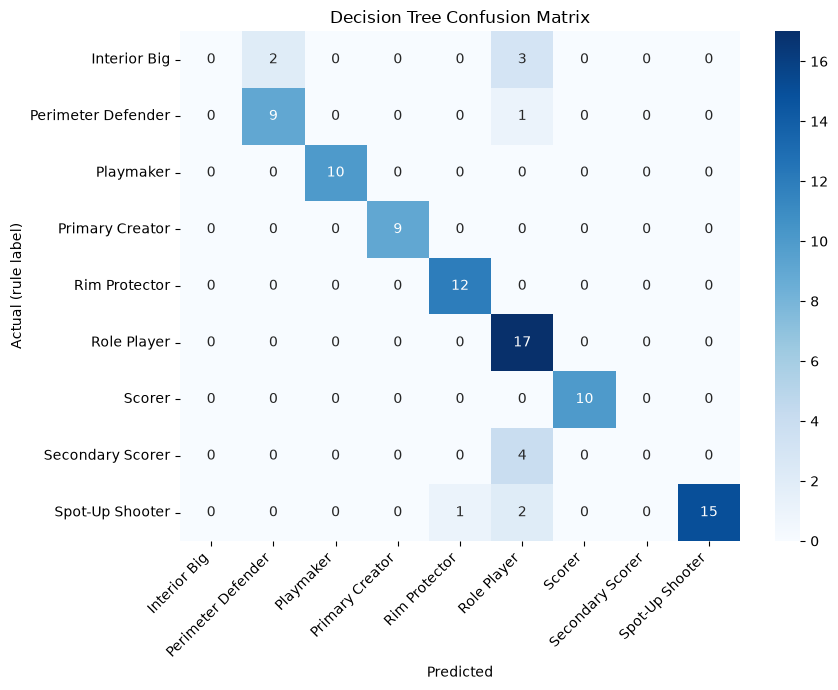

In [25]:
#Checking how the tree predicts against our test data
y_pred = tree.predict(X_test)
labels = tree.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)

#visual from AI
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual (rule label)')
plt.title('Decision Tree Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

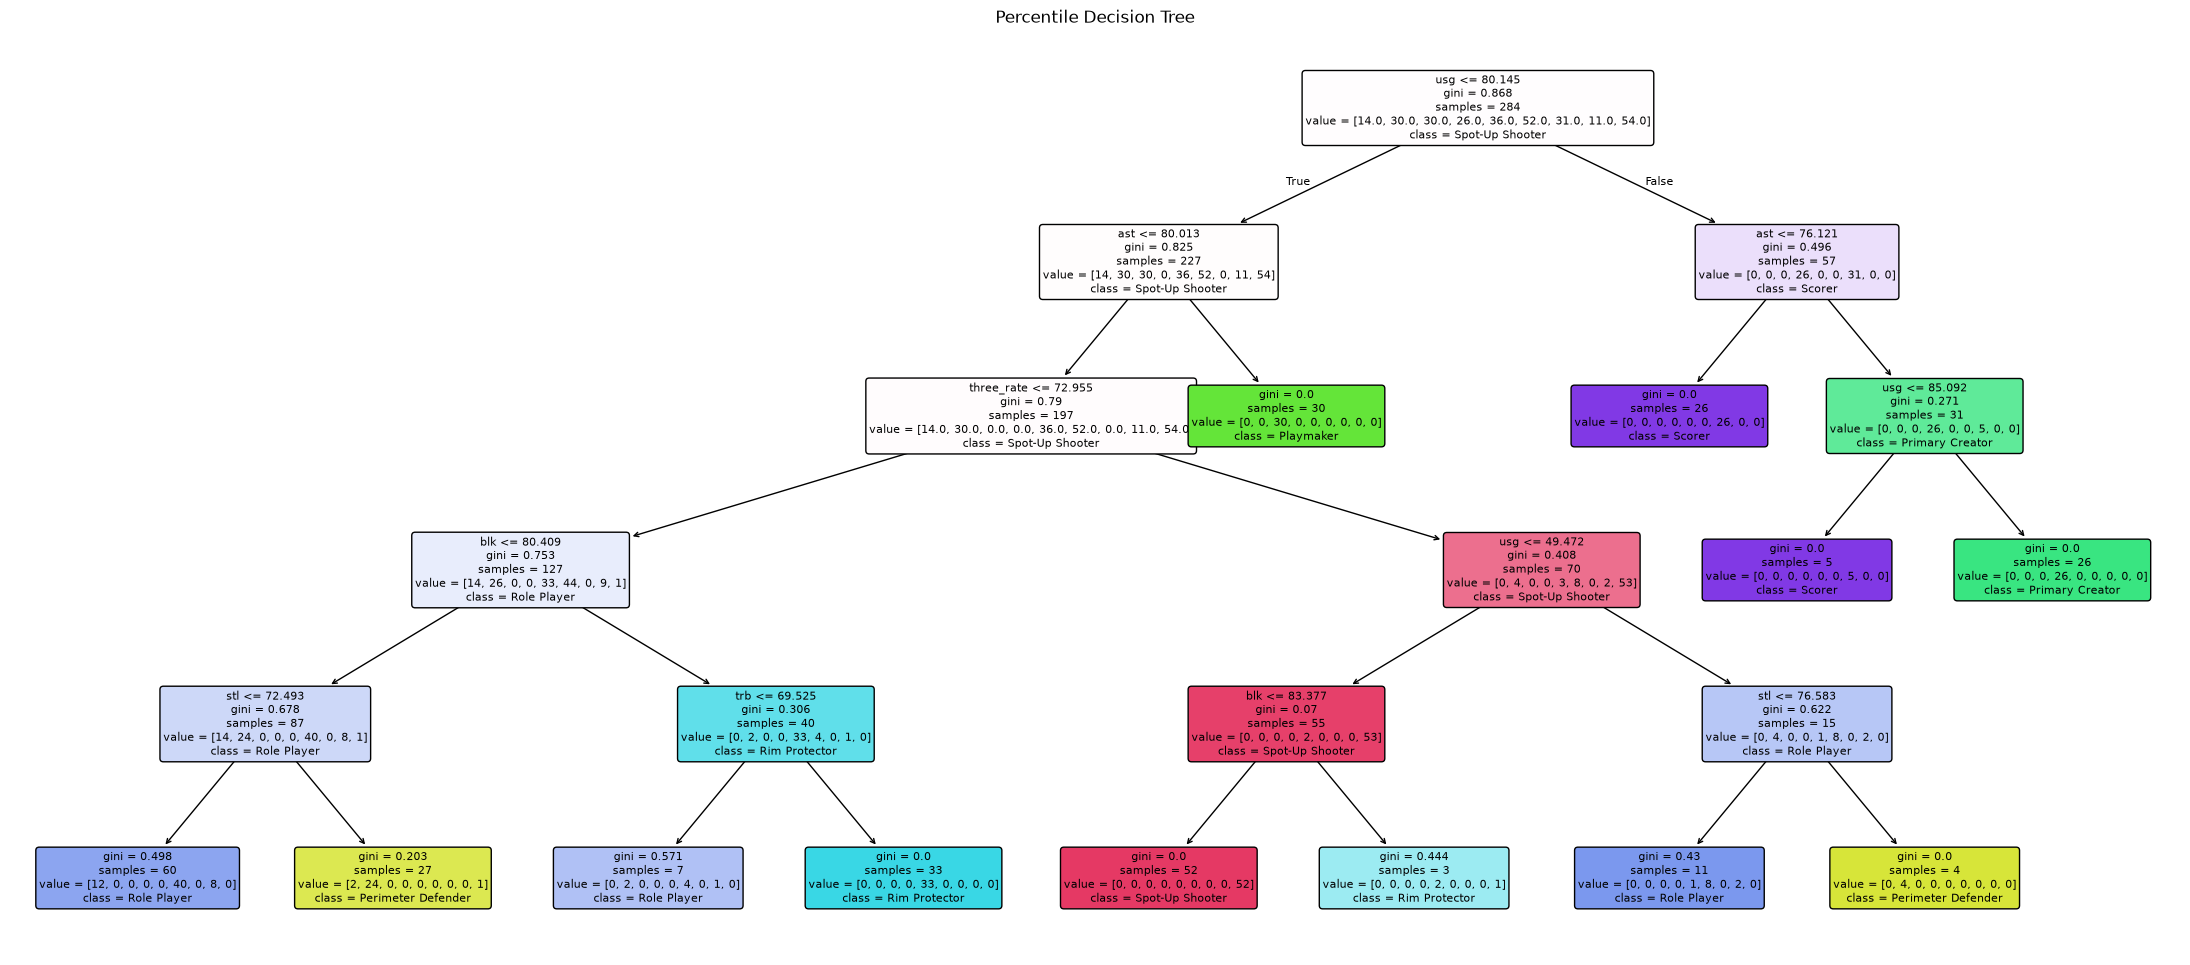

|--- usg <= 80.15
|   |--- ast <= 80.01
|   |   |--- three_rate <= 72.96
|   |   |   |--- blk <= 80.41
|   |   |   |   |--- stl <= 72.49
|   |   |   |   |   |--- class: Role Player
|   |   |   |   |--- stl >  72.49
|   |   |   |   |   |--- class: Perimeter Defender
|   |   |   |--- blk >  80.41
|   |   |   |   |--- trb <= 69.53
|   |   |   |   |   |--- class: Role Player
|   |   |   |   |--- trb >  69.53
|   |   |   |   |   |--- class: Rim Protector
|   |   |--- three_rate >  72.96
|   |   |   |--- usg <= 49.47
|   |   |   |   |--- blk <= 83.38
|   |   |   |   |   |--- class: Spot-Up Shooter
|   |   |   |   |--- blk >  83.38
|   |   |   |   |   |--- class: Rim Protector
|   |   |   |--- usg >  49.47
|   |   |   |   |--- stl <= 76.58
|   |   |   |   |   |--- class: Role Player
|   |   |   |   |--- stl >  76.58
|   |   |   |   |   |--- class: Perimeter Defender
|   |--- ast >  80.01
|   |   |--- class: Playmaker
|--- usg >  80.15
|   |--- ast <= 76.12
|   |   |--- class: Scorer
|   |--- 

In [26]:
plt.figure(figsize=(28, 12))
plot_tree(tree, feature_names=list(X.columns), class_names=list(labels),
        filled=True, rounded=True, fontsize=8)
plt.title('Percentile Decision Tree')
plt.show()

print(export_text(tree, feature_names=list(X.columns)))

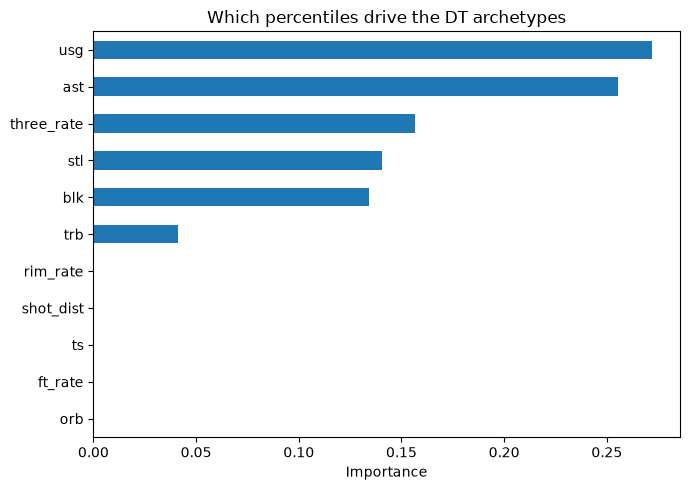

In [27]:
importances = pd.Series(tree.feature_importances_, index=X.columns).sort_values()

importances.plot(kind='barh', figsize=(7, 5))
plt.xlabel('Importance')
plt.title('Which percentiles drive the DT archetypes')
plt.tight_layout()
plt.show()

In [28]:
#give examples of players to check against intuition 
for arch, group in pct.groupby('archetype'):
    names = group.sort_values('usg', ascending=False)['Player'].head(5).tolist()
    print(f'{arch}: {", ".join(names)}')

Interior Big: Domantas Sabonis, Day'Ron Sharpe, Ivica Zubac, Sandro Mamukelashvili, Leonard Miller
Perimeter Defender: Devin Carter, Paul George, Rob Dillingham, Trey Murphy III, Anthony Black
Playmaker: Andrew Nembhard, Jrue Holiday, Scottie Barnes, Jimmy Butler, T.J. McConnell
Primary Creator: Luka Dončić, Giannis Antetokounmpo, Jaylen Brown, Joel Embiid, Kawhi Leonard
Rim Protector: Jalen Duren, Evan Mobley, Naz Reid, Chet Holmgren, Derik Queen
Role Player: Jonathan Kuminga, Tre Mann, Caleb Love, De'Andre Hunter, Klay Thompson
Scorer: Victor Wembanyama, Jalen Green, Anthony Edwards, Michael Porter Jr., Shaedon Sharpe
Secondary Scorer: Zach LaVine, Anfernee Simons, GG Jackson II, Desmond Bane, Bobby Portis
Spot-Up Shooter: Tim Hardaway Jr., Tyrese Martin, Isaiah Joe, Moses Moody, Jordan Hawkins
